# Product matching: what we built, how we checked it, and what it can't do

This notebook explains the 2026 rework of a 2022 take-home challenge for readers who are **not**
machine-learning specialists. Every number shown here is read from `reports/metrics.json`, which
`pm evaluate` writes; nothing is typed by hand.

**The problem.** A marketplace receives product listings from many sellers. Each seller types the
product name their own way: `Refrigerador Consul CRM33 263 Litros Inox` and
`Refrigerador Frost Free 2 Portas CRM33 249L Inox 220v - Consul` are the same fridge. The challenge asks for three things:

- **(a)** the probability that two listings are the same product;
- **(b)** the type, category, brand, color and model of a product, read from its name, answering
  *"I don't know"* (None) when unsure;
- **(c)** the most relevant products for a short search such as *notebook sony 4 GB*.

**What changed since 2022.** The 2022 notebook (`legacy/challenge_v1.ipynb`) built reasonable pieces but
never measured whether they worked. The main change here is not a fancier model. It is that every
answer is now checked against labelled examples it never saw during training, next to the 2022
approach run on exactly the same examples. Those labels were produced by an AI assistant (Claude)
applying a written rule and have not yet been reviewed by a person (section 2).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display

from product_matching.config import REPORTS_DIR, LABELS_DIR, set_seeds
from product_matching.data import load_products

set_seeds()
pd.set_option("display.max_colwidth", 90)
metrics = json.loads((REPORTS_DIR / "metrics.json").read_text())
df = load_products()
NEW, OLD = "#2a78d6", "#eb6834"   # blue = new system, orange = 2022 baseline
print(f"{len(df):,} listings")

26,241 listings


## 1. The data, and why it is harder than it looks

Each listing has a name plus five fields filled in by the seller. Empty fields hold the word `None`.

In [2]:
fields = ["tipo", "categoria", "marca", "cor", "modelo"]
summary = pd.DataFrame({
    "empty (None)": [f"{df[f].isna().mean():.1%}" for f in fields],
    "distinct values": [df[f].nunique() for f in fields],
}, index=fields)
summary

,empty (None),distinct values
tipo,1.0%,484
categoria,13.4%,20
marca,0.0%,1304
cor,84.7%,17
modelo,77.6%,3707


Three facts about this data shaped every later decision:

1. **"None" means *the seller didn't fill it in*, not *the product has none*.** Most colors are empty,
   yet thousands of those names state a color ("... Preto", "... Inox").
2. **The `modelo` field is often wrong.** In about 40% of the filled values the model does not appear in
   the name, and many are another product's model entirely, e.g. an MP4 player labelled with a Sony TV model. So the dataset's own color and
   model fields cannot be used as the answer key; instead, 200 names were labelled by an AI assistant
   (Claude) reading the color and model off the name (not yet reviewed by a person).
3. **Brands and types are numerous.** 1,300+ brands and ~480 types. The 2022 classifiers only knew the
   top 20 of each and answered "other" for everything else.

In [3]:
from product_matching.extraction import alnum
m = df[df["modelo"].notna()]
in_name = [alnum(a) in alnum(b) for a, b in zip(m["modelo"], m["nome"])]
print(f"modelo filled: {len(m):,};  appears in the name: {sum(in_name):,};  does not: {len(m) - sum(in_name):,}")
m.loc[[not x for x in in_name], ["nome", "modelo"]].sample(5, random_state=1)

modelo filled: 5,876;  appears in the name: 3,550;  does not: 2,326


,nome,modelo
6272,Dellar DGR 161 Multifuncional,cmp25
15358,Oxford Quartier Bamboo 20 Peças,wd9102
587,Mixlaser MiniFlip MP438 2GB,ln46d550
12502,Philips SatinPerfect HP6576,hp6576/10
6741,Câmera Digital PL20 14.2MP - Samsung,76stx


## 2. How we know whether it works: the answer key

There was no labelled data, so the labels were produced by an AI assistant (Claude) applying the
written rule below; they have **not yet been reviewed by a person**. All label files are plain CSVs in
`labels/` and can be edited; `pm evaluate` recomputes every number from them. `pm review-sample` and
`pm review-agreement` support a blind human review (see the README).

| What | How many | How they were picked |
|---|---|---|
| Listing pairs: same product or not | 800 | 350 that share a model code, 300 near-lookalikes, 150 random pairs of the same type |
| Names with color and model read off the name | 200 | random listings from the held-out set |
| Search queries with judged results | 30 queries, 1,237 judgments | each system's top 10 for every query, plus extra matches found by a text pattern |

**What "same product" means here:** the same manufacturer model, with no *conflicting* variant (color,
voltage, capacity, size) where both listings state one. A detail stated by only one listing is not a
conflict. So `Logic FL670 4GB` and `Logic FL670 8GB` are different products, while `Câmera Canon A800`
and `Câmera Canon A800 Vermelha` are the same.

**Held-out data.** Each labelled set is split. Models and every setting (thresholds, regularization)
are chosen on the training part only; the numbers below are on the part they never saw. Listings that
are near-copies of each other are kept on the same side of the split.

In [4]:
pairs = pd.read_csv(LABELS_DIR / "pairs.csv")
t = pairs.groupby("source")["label"].agg(pairs="count", same_product="sum")
t["share same"] = (t["same_product"] / t["pairs"]).map("{:.0%}".format)
t

,pairs,same_product,share same
source,,,
code,350,134,38%
neighbour,300,5,2%
random,150,0,0%


Almost all true duplicates share a model code; near-lookalikes without a shared code are almost always
*different* products (often the same product line in another color or size). That is exactly why plain
text similarity, the 2022 answer, is a poor judge.

## 3. (a) Are these two listings the same product?

**How it works**

1. *Shortlist.* Comparing all 26k listings with each other means 344 million pairs. We only score pairs
   that share a model code or are among each other's 10 most similar names (by spelling and by meaning).
2. *Describe each pair with 14 numbers*: how similar the names are, whether they share a rare model
   code, whether both state a capacity / voltage / color and they differ, whether the brands agree.
3. *Turn those numbers into a probability* with a logistic regression trained on 500 labelled pairs.
   This simple model is easy to calibrate and to explain, which matters with this few labels.

In [5]:
a = metrics["matching"]
rows = {"2022: cosine similarity": a["baseline_2022"], "embedding cosine (ablation)": a["embedding_cosine"],
        "new: calibrated model": a["new"]}
pd.DataFrame({k: {"precision": v["precision"], "recall": v["recall"], "F1": v["f1"],
                  "F1 95% CI": v["f1_ci95"], "PR-AUC": v["pr_auc"], "Brier": v["brier"]}
              for k, v in rows.items()}).T

,precision,recall,F1,F1 95% CI,PR-AUC,Brier
2022: cosine similarity,0.2341,0.9231,0.3735,"[0.2927, 0.4444]",0.1931,0.3074
embedding cosine (ablation),0.221,0.7692,0.3433,"[0.2653, 0.4188]",0.2434,0.7123
new: calibrated model,0.88,0.8462,0.8627,"[0.7865, 0.9286]",0.9432,0.0342


**How to read this.** *Precision*: when the system says "same product", how often it is right.
*Recall*: of the true duplicates, how many it finds. *F1* combines both. *PR-AUC* measures how well the
scores rank duplicates above non-duplicates, regardless of threshold. *Brier* is the average squared
gap between the stated probability and what happened (0 is perfect).

The 2022 approach found most duplicates, but at a threshold that catches them it also flagged
roughly three wrong pairs for every right one. The new model is right about 9 times in 10 and finds
about 85% of the duplicates.

**Is a "0.8" really 80%?** The chart below groups held-out pairs by predicted probability and shows how
often they really were duplicates. Points on the diagonal mean the probabilities can be taken at face
value. Most pairs sit near 0 or 1; the middle bins hold only a handful of pairs each (marker size shows
how many), so their zig-zag is noise, not a pattern.

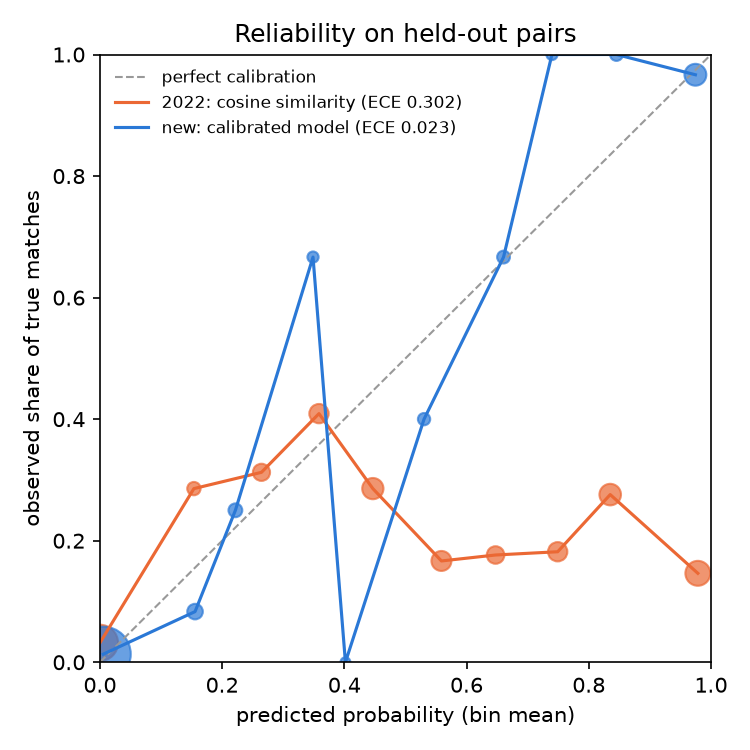

In [6]:
display(Image(filename=str(REPORTS_DIR / "figures" / "reliability.png"), width=420))

**What the model learned** (larger magnitude = more influence; features are on a common scale).
Sharing a *rare* model code and similar wording push toward "same"; a capacity or color conflict pushes
strongly toward "different".

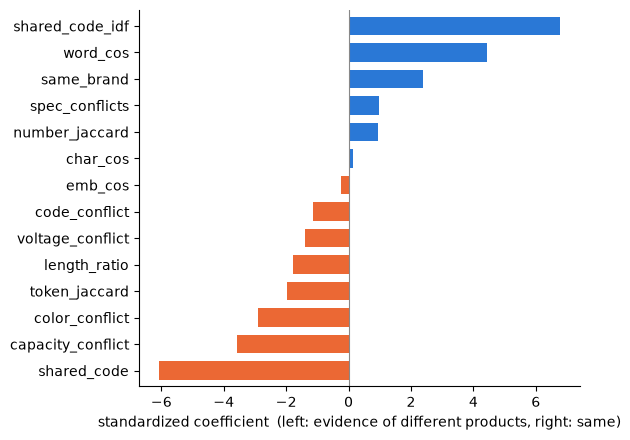

In [7]:
coef = pd.Series(a["model"]["coefficients"]).sort_values()
ax = coef.plot.barh(color=[OLD if v < 0 else NEW for v in coef], figsize=(6, 4.5), width=0.7)
ax.axvline(0, color="#888", lw=0.8)
ax.set_xlabel("standardized coefficient  (left: evidence of different products, right: same)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

**The 2022 notebook's own example.** It presented rows 2 and 45 as "very similar products" with a
similarity of 0.91. They are two different cutlery sets (Laguna 66906760 and Athenas 66940020).

In [8]:
from product_matching.service import Service
service = Service.load()   # built by `pm build`
r2, r45 = df.loc[2], df.loc[45]
print(r2["nome"]); print(r45["nome"])
service.match({"nome": r2["nome"], "marca": r2["marca"]}, {"nome": r45["nome"], "marca": r45["marca"]})

Faqueiro Tramontina Inox Laguna 66906760 20
Faqueiro Tramontina Inox Athenas 66940020 101


W1104 11:31:53.790000 4781 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

{'probability': 0.0, 'same_product': False, 'threshold': 0.337}

## 4. (b) Reading type, category, brand, color and model from a name

- **Type and category**: a text classifier, which answers only when it is confident enough.
- **Brand**: first a dictionary of brand names that reliably mark a brand when they appear in a name;
  otherwise the classifier.
- **Color**: color words found in the name.
- **Model**: candidate code-like tokens in the name, ranked by a small model trained on listings whose
  `modelo` label really appears in the name.

The confidence needed before answering is set on a validation slice of the training data so that answers
are right about 95% of the time; below it the system returns None.

In [9]:
e = metrics["extraction"]["fields"]
pd.DataFrame({f: {
    "classes": e[f]["n_classes_train"],
    "majority class, overall": e[f]["baseline_majority"]["accuracy_all"],
    "2022: answered": e[f]["baseline_2022"]["coverage"],
    "2022: overall": e[f]["baseline_2022"]["accuracy_all"],
    "new: answered": e[f]["new"]["coverage"],
    "new: accuracy of answers": e[f]["new"]["accuracy_answered"],
    "new: overall": e[f]["new"]["accuracy_all"]} for f in ("tipo", "categoria", "marca")}).T.round(3)

,classes,"majority class, overall",2022: answered,2022: overall,new: answered,new: accuracy of answers,new: overall
tipo,477.0,0.034,0.292,0.280,0.966,0.961,0.928
categoria,20.0,0.256,0.894,0.834,1.000,0.959,0.959
marca,1260.0,0.032,0.217,0.213,0.991,0.956,0.948


*Answered* is the share of listings that get an answer; *overall* counts an abstention as wrong.
The 2022 classifiers were accurate when they answered, but for type and brand they answered for fewer than a
third of listings, because anything outside the top 20 became "other".

The chart shows the trade-off the confidence threshold controls: answering fewer listings (most confident
first) gives more accurate answers.

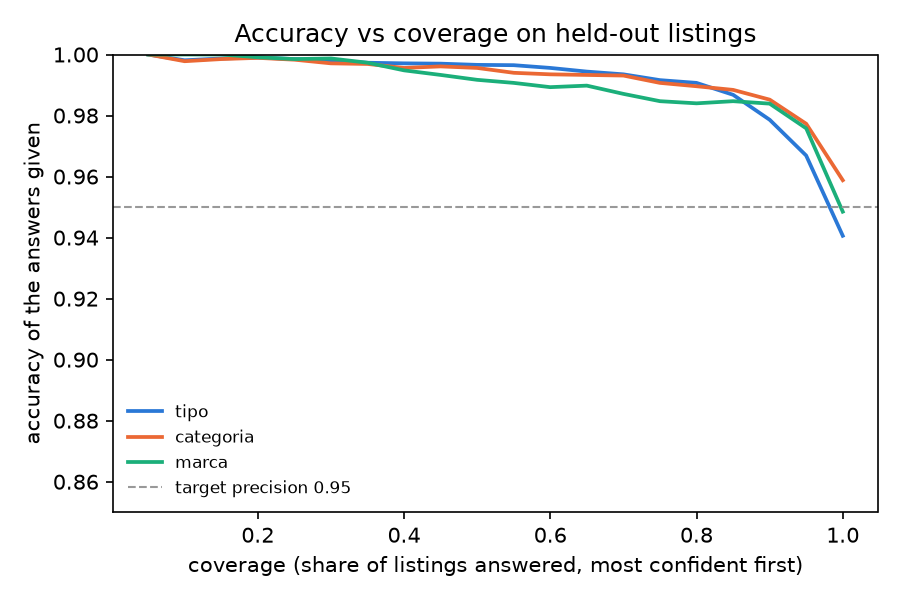

In [10]:
display(Image(filename=str(REPORTS_DIR / "figures" / "coverage.png"), width=520))

In [11]:
pd.DataFrame({f: {
    "present in name": f"{e[f]['gold_present']}/{e[f]['n_test']}",
    "always answer None": e[f]["baseline_always_none"]["accuracy"],
    "2022 (copy nearest listing)": e[f]["baseline_2022"]["accuracy"],
    "dataset field as-is": e[f]["dataset_field"]["accuracy"],
    "new": e[f]["new"]["accuracy"],
    "new: precision": e[f]["new"]["precision"],
    "new: recall": e[f]["new"]["recall"]} for f in ("cor", "modelo")}).T

,present in name,always answer None,2022 (copy nearest listing),dataset field as-is,new,new: precision,new: recall
cor,65/200,0.675,0.675,0.755,0.915,0.9107,0.7846
modelo,95/200,0.525,0.525,0.59,0.795,0.8194,0.6211


For color and model, "None" is often the right answer, so *always answer None* is a strong baseline:
it is right whenever the name states no color. The 2022 method scores exactly that, for a revealing
reason: it copied color and model from the nearest listing, and because the query's empty fields
were turned into the word "none", the nearest listing always had empty fields too.

Examples, including abstentions:

In [12]:
examples = ["Notebook Sony Vaio VPC-EG13EB/L Intel Core i3 4GB 500GB Azul",
            "Kit Presente Natal",
            "Lavadora 9Kg BWL09B Ative! Branca 220v - Brastemp"]
pd.DataFrame({n: {k: v["value"] for k, v in service.extract(n).items()} for n in examples}).T

,tipo,categoria,marca,modelo,cor
Notebook Sony Vaio VPC-EG13EB/L Intel Core i3 4GB 500GB Azul,Notebook,Informática,Sony,vpceg13eb,Azul
Kit Presente Natal,NaN,Kit,Embrasil,NaN,NaN
Lavadora 9Kg BWL09B Ative! Branca 220v - Brastemp,Lavadora de Roupa,Eletrodomésticos,Brastemp,bwl09b,Branco


## 5. (c) Search

Four ways to rank listings for a query, all using the same text cleanup (so `4 GB`, `4gb` and `4096 MB` match):

- **BM25**: classic keyword ranking. Rare words count more, and long names count less.
- **Character n-grams**: compares 3-5 letter fragments, so it tolerates typos (`taif` vs `taiff`).
- **Embeddings** (`multilingual-e5-small`): a neural model that maps text to meaning, so `geladeira`
  matches `refrigerador`.
- **Hybrid**: merges the BM25 and embedding rankings (reciprocal rank fusion).

*nDCG@10* scores the top 10 results: 1.0 means the best available listings, in the best order.

In [13]:
s = metrics["search"]["systems"]
pd.DataFrame({k: {"nDCG@10": v["ndcg@10"], "95% CI": v["ndcg@10_ci95"],
                  "recall@10": v["recall@10"], "exact matches in top 10": v["recall@10_grade2"]}
              for k, v in s.items()}).T

,nDCG@10,95% CI,recall@10,exact matches in top 10
baseline_2022,0.629,"[0.5188, 0.7342]",0.81,0.517
bm25,0.8468,"[0.7596, 0.927]",0.93,0.7793
char_ngram,0.8051,"[0.7217, 0.8833]",0.9333,0.7115
embedding_e5_small,0.7709,"[0.6691, 0.8658]",0.8433,0.7148
hybrid_bm25_e5_small,0.8483,"[0.7655, 0.9234]",0.9167,0.8022
embedding_e5_base,0.7122,"[0.6174, 0.8081]",0.7833,0.6385


BM25 and the hybrid are tied: their intervals overlap almost entirely, and 30 queries cannot separate
them. Both are clearly better than 2022. The API uses the hybrid because it also covers synonyms that
keyword search misses. The larger embedding model (e5-base) did *worse* than the small one here, so bigger is not
automatically better.

Per query (each row is one query):

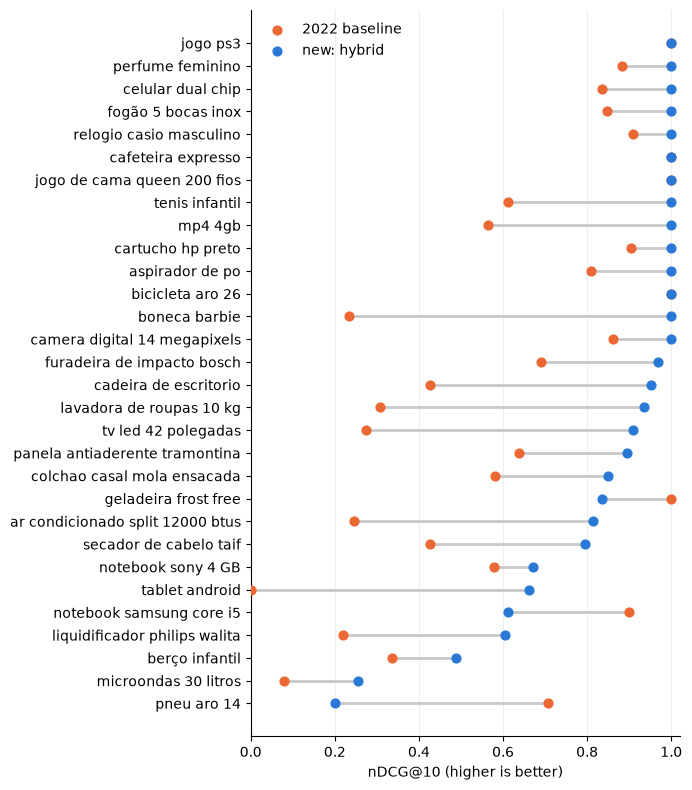

In [14]:
pq = pd.DataFrame(metrics["search"]["per_query_ndcg@10"]).T
pq = pq.sort_values("hybrid_bm25_e5_small")
fig, ax = plt.subplots(figsize=(7, 8))
y = range(len(pq))
ax.hlines(y, pq["baseline_2022"], pq["hybrid_bm25_e5_small"], color="#c9c9c9", lw=2)
ax.scatter(pq["baseline_2022"], y, color=OLD, s=40, label="2022 baseline", zorder=3)
ax.scatter(pq["hybrid_bm25_e5_small"], y, color=NEW, s=40, label="new: hybrid", zorder=3)
ax.set_yticks(list(y), pq["query"])
ax.set_xlabel("nDCG@10 (higher is better)")
ax.set_xlim(0, 1.02)
ax.legend(loc="upper left", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#eee")
plt.tight_layout()

In [15]:
d = pq["hybrid_bm25_e5_small"] - pq["baseline_2022"]
print(f"new better on {(d > 0.005).sum()} queries, tied on {(d.abs() <= 0.005).sum()}, worse on {(d < -0.005).sum()}:")
pq.loc[d < -0.005, ["query", "baseline_2022", "hybrid_bm25_e5_small"]]

new better on 23 queries, tied on 4, worse on 3:


,query,baseline_2022,hybrid_bm25_e5_small
q27,pneu aro 14,0.7058,0.1993
q23,notebook samsung core i5,0.8988,0.611
q02,geladeira frost free,1.0,0.8365


Where 2022 wins, it is because its query was enriched with a predicted type and brand. The new search
ranks by words and meaning only. So for *pneu aro 14* the number "14" pulls in kids' bikes, a kettle
and a flashlight; *geladeira frost free* mixes in two frost-free freezers; *notebook samsung core i5*
mixes in i5 notebooks from other brands. Same lesson as the example below: the query's product type
(and brand) should steer the ranking.

The challenge's own example, top 5 from the new system. The first hit is a Sony **4GB memory stick**:
the words match and the meaning is close, but it is not a notebook. Fixing that needs the query's product
type (part b) to steer the ranking, which is listed under next steps.

In [16]:
pd.DataFrame(service.search("notebook sony 4 GB", k=5))[["nome", "tipo", "marca"]]

,nome,tipo,marca
0,Memory Stick Pro Duo 4GB - Sony,Cartão de Memória,Sony
1,"Notebook Sony Intel® Core i3-2310M - 2.10GHz, VPCEH10EB/W, 4GB, 320GB, 15,5?, Webcam, ...",Notebook,Sony
2,"Notebook Sony Vaio Intel® Core? i3-2310M, VPC-EG13EB/P, 4GB, HD 500GB, 14?, Webcam, Wi...",Notebook,Sony
3,"Notebook Sony Intel® Core? i5-2410M 2.30GHz Turbo Boost 2.90GHz, VPCF223FB/B, 4GB, 500...",Notebook,Sony
4,"Notebook Sony AMD Phenom? II Triple-Core P820, VPC-EE25FB/BI, 4GB, HD 500GB, 15,5""",Notebook,Sony


## 6. Limitations: what these numbers do not show

- **Small answer key.** 52 held-out duplicate pairs and 30 queries. The confidence intervals are wide
  (matching F1 roughly ±0.07, search nDCG roughly ±0.08); treat differences smaller than that as ties.
- **The labels are AI-generated and unreviewed.** Every label was produced by an AI assistant (Claude)
  applying the written rule (with an `unsure` flag on hard cases); no person has checked them yet, so the
  numbers measure agreement with those labels.
- **The test pairs are not a random sample of the catalogue.** They over-represent hard cases (shared
  codes, lookalikes), which is where the decisions matter, but precision over *all* candidate pairs would
  differ.
- **Duplicates without a shared code are rare in the labels** (5 of 139), so the model has little evidence
  about them, and the shortlist step's 100% recall is measured mostly on pairs it was designed to find.
- **Type, category and brand are scored against seller-entered labels**, which contain their own mistakes.
- **The model extractor does not know when a name has no model** beyond "no code-like token"; its
  abstention threshold was tuned on names that all had one (see the precision of 0.82 vs a 0.90 target).
- **Search judgments are pooled** from the systems being compared; a listing that no system found is
  assumed irrelevant.

## 7. Next steps

- Use the predicted product type of the query to filter or boost search results (fixes the memory-stick case).
- A blind human review of the `unsure` rows and a random test sample (`pm review-sample`), and more pairs
  without shared codes.
- Cluster listings into product groups using the pair probabilities.